### Ceci est un projet Bancaire qui consiste a analysé les données des clients d'une Banque et determiné si un client  peut beneficier d'un pret ou non

## Les étapes du projets:

### 1. Comprendre la problematique(Le probleme metier : A Quel type de client peut on accorder un credit ?)
### 2. Collecte de données
### 3. Netoyage des données
### 4. Analyse exploratoire(Visualisation)
### 5. Préparation du modele(Modele du machine learning)
### 6. Evaluer les performances du modele
### 7. Deploiement du modele

In [1]:
import pandas as pd             # Pour la manipulation des données
import numpy as np              # Pour les calculs numériques
import matplotlib.pyplot as plt # Pour la visualisation des données
import seaborn as sns           # Pour la visualisation avancée des données
import pickle                   # Pour la sérialisation des objets Python(utilsé pour generer le model qui sera intégré a lappli)
                                # La sérialisation consiste à transformer un objet Python en données que l'on peut enregistrer

In [2]:
from google.colab import drive  # Pour la connexion a google colab
import os


### Connection a google drive pour utilisé les fichier

In [3]:
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:

print(os.listdir('/content/drive/MyDrive/DataScienceProject'))

['test_Y3wMUE5_7gLdaTN.csv', 'train_u6lujuX_CVtuZ9i.csv']


### Charger les données dans une variable local: data

In [5]:
df = pd.read_csv('/content/drive/MyDrive/DataScienceProject/train_u6lujuX_CVtuZ9i.csv')

In [6]:
df.head(10)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N


## Comprehesion des colonne:

#### ==> Loan_ID: l'identifiant de chaque client
#### ==> Gender : Le genre du demandeur: Masculin ou feminin
#### ==> Married : Situation matrimonial du demandeur: Marié ou celibataire	
#### ==> Dependents : Nombre Personne a charge du demandeur : 0, 1, 2 ou 3 etc...
#### ==> Education : Niveau d'etude du demandeur: Diplomé ou non diplomé
#### ==> Self_Employed : Le demandeur est il un travailleur independant ou dependant
#### ==> ApplicantIncome : Revenu du candidat ou client voulant le pret
#### ==> CoapplicantIncome : Revenu du co-demandeur : Epoux si c'est une femme, epouse si c'est un homme
#### ==> LoanAmount : Montant du pret
#### ==> Loan_Amount_Term: Durée du rembourssement du pret(Exemple: la valeur 360.0 signifie que le pret doit etre rembourser durant 360 mois soit 30 ans)
#### ==> Credit_History  : Historique des credit du demandeur( 1 si la personne a eu u bon historique et 0 si non)
#### ==> Property_Area   : représente la zone géographique dans laquelle se trouve le bien immobilier concerné par le prêt(rural,urbaine,semiurrbaine etc..)

### --> Nb: Dans ce projet le prêt est bien une somme d'argent, mais il s'agit plus précisément d'un prêt immobilier ou d'un prêt destiné à financer un bien immobilier.

#### ==> Loan_Status     : status du pret (: validé, N:refusé)


### Afficher toute la base données

In [7]:
# pd.set_option('display.max_rows', df.shape[0]) # Affiche toutes les lignes du DataFrame
# df

In [8]:
pd.set_option('display.max_rows', 10) # Affiche les premieres et dernieres lignes du DataFrame
df


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


### Verification des valeurs manquantes 

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


### Afficher les valeurs manquantes pour chaque colonne, triées par ordre décroissant

In [10]:
df.isnull().sum().sort_values(ascending=False) 

,0
Credit_History,50
Self_Employed,32
LoanAmount,22
Dependents,15
Loan_Amount_Term,14
...,...
Loan_ID,0
CoapplicantIncome,0
ApplicantIncome,0
Property_Area,0


### Statistique descriptive des données

In [11]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


### Au cas ou on trouvait par exemple pour ApplicantIncome	une valeur minimal -4 et une valeur maximale: 81000.000000 alors yaurait un probleme

### Affichage des variables categorielle

In [12]:
df.describe(include ='O') # Pour les variables catégorielles

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
count,614,601,611,599,614,582,614,614
unique,614,2,2,4,2,2,3,2
top,LP002990,Male,Yes,0,Graduate,No,Semiurban,Y
freq,1,489,398,345,480,500,233,422


### Interpretation de frequence : Gender par exemple : 489 personne sur les 601 renseigné sont des homme et donc Male

### Le top identifie la valeur dominante ou la plus frequentes

## Gestion des valeurs manquantes:

### 1. S'il n'ya pas trop de valeur manquante, alors on peut les supprimé 

### 2. Dans le cadre de ce projet on remarque qu'il ya un nombre important de valeur manquante, doonc on doit juste les renseigné et non les supprimé

### NB: Les variables categorielle manquantes seront remplacé par les valeurs frequentes

### Pour les variables numerique manquantes elles seront remplacé par la valeur d'a coté tout simplement par exemple si on a une valeur manquante dans une case et la valeur precedent cette case en question est 3 alors la valeur manquante sera remplacé par 3.

## Pour procédé nous allons divisé la base de données en deux parties: Une parties contenant des variables categorielles et une autre contenant des variables numeriques

In [13]:
# Renseignement des valeurs manquantes en fonction des type de variables
# Creation des liste pour chaq categorie

var_categorique = []
var_numerique = []

# On verifie le type de chaque colonne, et on les ajoute dans la liste correspondante

for index, value in enumerate(df.dtypes):       # enumarate permet de recuperer deux info a la fois, index et value
    if value == 'object':
        var_categorique.append(df.iloc[:, index])  # df.iloc[:, index] signifie prend toutes les lignes(:) de la colonne index
    else:
        var_numerique.append(df.iloc[:, index])
var_categorique



[0      LP001002
 1      LP001003
 2      LP001005
 3      LP001006
 4      LP001008
          ...   
 609    LP002978
 610    LP002979
 611    LP002983
 612    LP002984
 613    LP002990
 Name: Loan_ID, Length: 614, dtype: object,
 0        Male
 1        Male
 2        Male
 3        Male
 4        Male
         ...  
 609    Female
 610      Male
 611      Male
 612      Male
 613    Female
 Name: Gender, Length: 614, dtype: object,
 0       No
 1      Yes
 2      Yes
 3      Yes
 4       No
       ... 
 609     No
 610    Yes
 611    Yes
 612    Yes
 613     No
 Name: Married, Length: 614, dtype: object,
 0       0
 1       1
 2       0
 3       0
 4       0
        ..
 609     0
 610    3+
 611     1
 612     2
 613     0
 Name: Dependents, Length: 614, dtype: object,
 0          Graduate
 1          Graduate
 2          Graduate
 3      Not Graduate
 4          Graduate
            ...     
 609        Graduate
 610        Graduate
 611        Graduate
 612        Graduate
 613   

In [14]:
var_numerique

[0      5849
 1      4583
 2      3000
 3      2583
 4      6000
        ... 
 609    2900
 610    4106
 611    8072
 612    7583
 613    4583
 Name: ApplicantIncome, Length: 614, dtype: int64,
 0         0.0
 1      1508.0
 2         0.0
 3      2358.0
 4         0.0
         ...  
 609       0.0
 610       0.0
 611     240.0
 612       0.0
 613       0.0
 Name: CoapplicantIncome, Length: 614, dtype: float64,
 0        NaN
 1      128.0
 2       66.0
 3      120.0
 4      141.0
        ...  
 609     71.0
 610     40.0
 611    253.0
 612    187.0
 613    133.0
 Name: LoanAmount, Length: 614, dtype: float64,
 0      360.0
 1      360.0
 2      360.0
 3      360.0
 4      360.0
        ...  
 609    360.0
 610    180.0
 611    360.0
 612    360.0
 613    360.0
 Name: Loan_Amount_Term, Length: 614, dtype: float64,
 0      1.0
 1      1.0
 2      1.0
 3      1.0
 4      1.0
       ... 
 609    1.0
 610    1.0
 611    1.0
 612    1.0
 613    0.0
 Name: Credit_History, Length: 614, dtype: f

### Convertion des listes en en base de données ou en dataframe

In [15]:
var_categorique = pd.DataFrame(var_categorique).transpose() # .transpose() permet de transposer le DataFrame, c'est-à-dire d'inverser les lignes et les colonnes
var_categorique

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,Urban,Y
4,LP001008,Male,No,0,Graduate,No,Urban,Y
...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,Urban,Y


In [16]:
var_numerique = pd.DataFrame(var_numerique).transpose()
var_numerique

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
0,5849.0,0.0,NaN,360.0,1.0
1,4583.0,1508.0,128.0,360.0,1.0
2,3000.0,0.0,66.0,360.0,1.0
3,2583.0,2358.0,120.0,360.0,1.0
4,6000.0,0.0,141.0,360.0,1.0
...,...,...,...,...,...
609,2900.0,0.0,71.0,360.0,1.0
610,4106.0,0.0,40.0,180.0,1.0
611,8072.0,240.0,253.0,360.0,1.0
612,7583.0,0.0,187.0,360.0,1.0


### Var_categorique : Remplacement des valeurs manquantes par des valeurs qui se repete le plus

In [17]:
# Var_categorique : Remplacement des valeurs manquantes par des valeurs qui se repete le plus
var_categorique = var_categorique.fillna(var_categorique.mode().iloc[0])   # fillna() permet de remplacer les valeurs manquantes par la valeur qui se repete le plus (mode()) dans chaque colonne. mode() retourne un DataFrame, donc on utilise iloc[0] pour recuperer la premiere ligne du DataFrame mode()
var_categorique.isnull().sum() # On verifie si les valeurs manquantes ont été remplacées

# mode() cherche, pour chaque colonne, la valeur qui apparaît le plus souvent.

,0
Loan_ID,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
Property_Area,0
Loan_Status,0


In [18]:
var_categorique['Married'].value_counts() # value_counts() permet de compter le nombre d'occurrences de chaque valeur dans la colonne 'Married'

,count
Married,
Yes,401
No,213


In [19]:
# Var_numerique: Remplacement des valeurs manquantes par la valeurs qui precede la valeur manquante
var_numerique = var_numerique.fillna(method='bfill')       # bfill() permet de remplacer les valeurs manquantes par la valeur qui precede la valeur manquante
var_numerique.isnull().sum() # On verifie si les valeurs manquantes ont été remplacées


/tmp/ipykernel_1056/696413677.py:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  var_numerique = var_numerique.fillna(method='bfill')       # bfill() permet de remplacer les valeurs manquantes par la valeur qui precede la valeur manquante


,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0
Credit_History,0


In [20]:
var_numerique['LoanAmount'].value_counts() # value_counts() permet de compter le nombre d'occurrences de chaque valeur dans la colonne 'LoanAmount'

,count
LoanAmount,
120.0,20
110.0,17
100.0,16
160.0,15
187.0,13
...,...
292.0,1
142.0,1
350.0,1


In [21]:
var_categorique

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,Urban,Y
4,LP001008,Male,No,0,Graduate,No,Urban,Y
...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,Urban,Y


In [22]:
var_numerique

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
0,5849.0,0.0,128.0,360.0,1.0
1,4583.0,1508.0,128.0,360.0,1.0
2,3000.0,0.0,66.0,360.0,1.0
3,2583.0,2358.0,120.0,360.0,1.0
4,6000.0,0.0,141.0,360.0,1.0
...,...,...,...,...,...
609,2900.0,0.0,71.0,360.0,1.0
610,4106.0,0.0,40.0,180.0,1.0
611,8072.0,240.0,253.0,360.0,1.0
612,7583.0,0.0,187.0,360.0,1.0


## Changement de quelques valeurs pour l'analyse

In [23]:
# Remplacer de la variable target(loan_status) qui est actuellement Y ou N mais sera remplacé par 1 ou 0 pour faciliter l'entrainement du model
var_target = var_categorique['Loan_Status'].map({'Y': 1, 'N': 0})
var_categorique.drop('Loan_Status', axis=1, inplace=True) # axis=1 signifie que l'on supprime la colonne 'Loan_status' et inplace=True signifie que l'on modifie le DataFrame var_categorique directement

In [24]:
var_target

,Loan_Status
0,1
1,0
2,1
3,1
4,1
...,...
609,1
610,1
611,1
612,1


In [25]:
# Remplacement des autres variables catégorielles par des variables numériques de maniere automatique avec scikit-learn

from sklearn.preprocessing import LabelEncoder

label_encoders = {}                    # Permet de stocker les encodeurs pour chaque variable catégorielle, afin de pouvoir les réutiliser plus tard si nécessaire
for column in var_categorique.columns: # Permet de parcourir toutes les colonnes du DataFrame var_categorique
    le = LabelEncoder()                # permet de créer un objet LabelEncoder pour chaque colonne
    var_categorique[column] = le.fit_transform(var_categorique[column]) # permet de transformer les valeurs catégorielles en valeurs numériques pour chaque colonne du DataFrame var_categorique
    label_encoders[column] = le          # permet de stocker l'encodeur pour chaque colonne dans le dictionnaire label_encoders
var_categorique

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area
0,0,1,0,0,0,0,2
1,1,1,1,1,0,0,0
2,2,1,1,0,0,1,2
3,3,1,1,0,1,0,2
4,4,1,0,0,0,0,2
...,...,...,...,...,...,...,...
609,609,0,0,0,0,0,0
610,610,1,1,3,0,0,0
611,611,1,1,1,0,0,2
612,612,1,1,2,0,0,2


In [26]:
# Suppression de la colonne Loan_id car il va pas servir a grande chose
var_categorique.drop('Loan_ID', axis=1, inplace=True) # axis=1 signifie que l'on supprime la colonne 'Loan_ID' et inplace=True signifie que l'on modifie le DataFrame df directement

In [27]:
var_categorique

,Gender,Married,Dependents,Education,Self_Employed,Property_Area
0,1,0,0,0,0,2
1,1,1,1,0,0,0
2,1,1,0,0,1,2
3,1,1,0,1,0,2
4,1,0,0,0,0,2
...,...,...,...,...,...,...
609,0,0,0,0,0,0
610,1,1,3,0,0,0
611,1,1,1,0,0,2
612,1,1,2,0,0,2


In [28]:
# Concatenation des variables numerique et categorique dans une seul variables et specifier la colonne target

X = pd.concat([var_numerique, var_categorique], axis=1) # axis=1 signifie que l'on concatene les colonnes des deux DataFrame var_numerique et var_categorique
y = var_target


In [29]:
X

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender,Married,Dependents,Education,Self_Employed,Property_Area
0,5849.0,0.0,128.0,360.0,1.0,1,0,0,0,0,2
1,4583.0,1508.0,128.0,360.0,1.0,1,1,1,0,0,0
2,3000.0,0.0,66.0,360.0,1.0,1,1,0,0,1,2
3,2583.0,2358.0,120.0,360.0,1.0,1,1,0,1,0,2
4,6000.0,0.0,141.0,360.0,1.0,1,0,0,0,0,2
...,...,...,...,...,...,...,...,...,...,...,...
609,2900.0,0.0,71.0,360.0,1.0,0,0,0,0,0,0
610,4106.0,0.0,40.0,180.0,1.0,1,1,3,0,0,0
611,8072.0,240.0,253.0,360.0,1.0,1,1,1,0,0,2
612,7583.0,0.0,187.0,360.0,1.0,1,1,2,0,0,2


In [30]:
y

,Loan_Status
0,1
1,0
2,1
3,1
4,1
...,...
609,1
610,1
611,1
612,1


# Fin de l'etape de  preparation de données

# Analyse exploratoire

### NB : Le but de l'analyse exploratoire c'est de comprendre notre base de données en utilisant des visuels

In [31]:
# Analyse exploratoire

# Variable target

y.value_counts()

,count
Loan_Status,
1,422
0,192


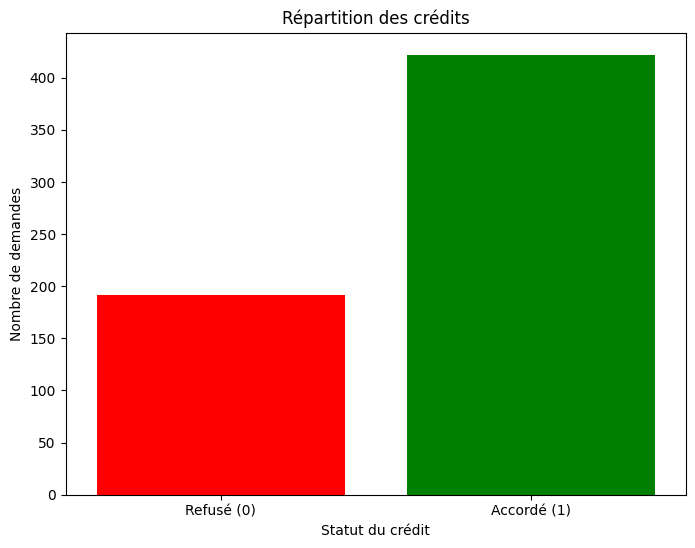

Pourcentage des crédits accordés : 68.73%
Pourcentage des crédits non accordés : 31.27%


In [32]:

plt.figure(figsize=(8, 6))

ax = sns.countplot(x=var_target, order=[0, 1])

# Couleur des graphiques 
ax.patches[0].set_facecolor('red')   # Couleur pour les crédits refusés
ax.patches[1].set_facecolor('green') # Couleur pour les crédits accordés

plt.title("Répartition des crédits")
plt.xlabel("Statut du crédit")
plt.ylabel("Nombre de demandes")
plt.xticks([0, 1], ["Refusé (0)", "Accordé (1)"])

plt.show()

# Calcul des pourcentages
pourcentage_accordes = (var_target == 1).mean() * 100
pourcentage_refuses = (var_target == 0).mean() * 100

print(f"Pourcentage des crédits accordés : {pourcentage_accordes:.2f}%")
print(f"Pourcentage des crédits non accordés : {pourcentage_refuses:.2f}%")

/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:718: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


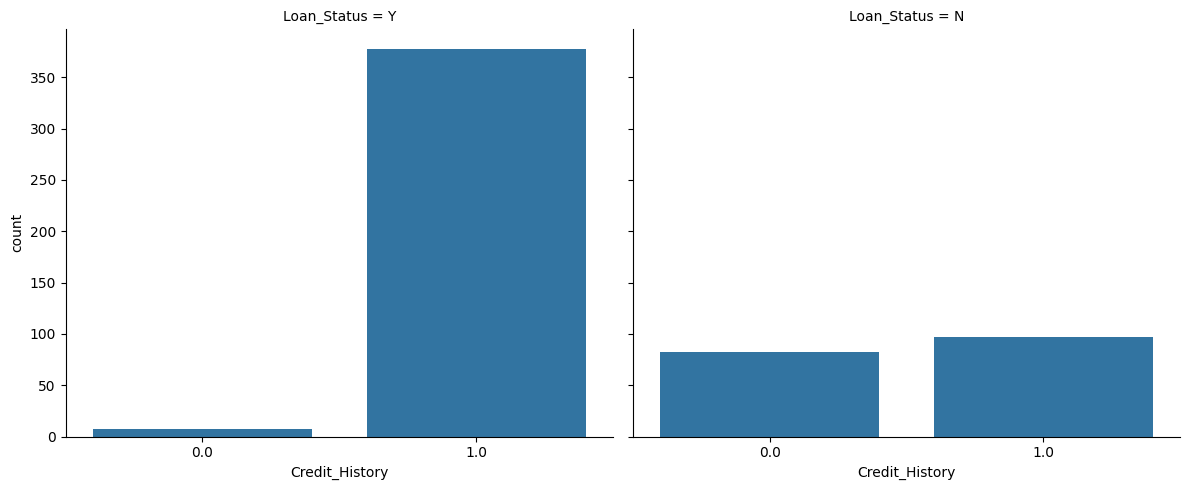

In [33]:
# Impacte de chaque variable sur le fait d'accorder un credit ou pas

# Credit_history

grid=sns.FacetGrid(df, col="Loan_Status", height=5, aspect=1.2)
grid.map(sns.countplot, "Credit_History")



### On remarque que sur la premiere figure (loan_status = yes) que la plus part des personne qui beneficie d'un credit ont un historique de credit
### Sur la deuxieme figure (loan_status = no) il ya un equilibre entre les credit accepté et refusé

/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:718: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


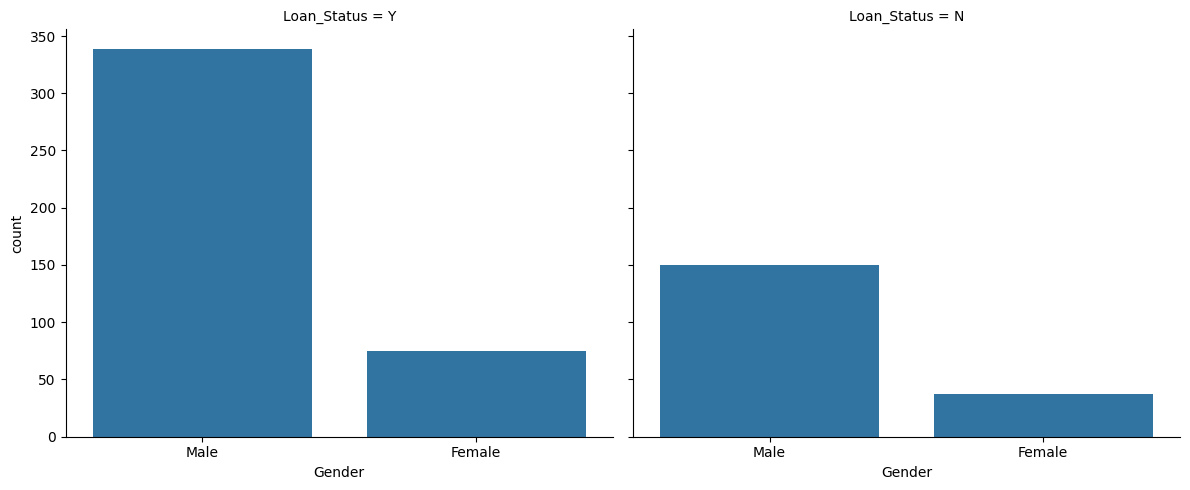

In [34]:
# Gender (Sexe)

grid=sns.FacetGrid(df, col="Loan_Status", height=5, aspect=1.2)
grid.map(sns.countplot, "Gender")


### Ici on remarque ce sont les hoe qui demande plus de credit et aussi qui beneficie le plus de crediit

/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:718: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


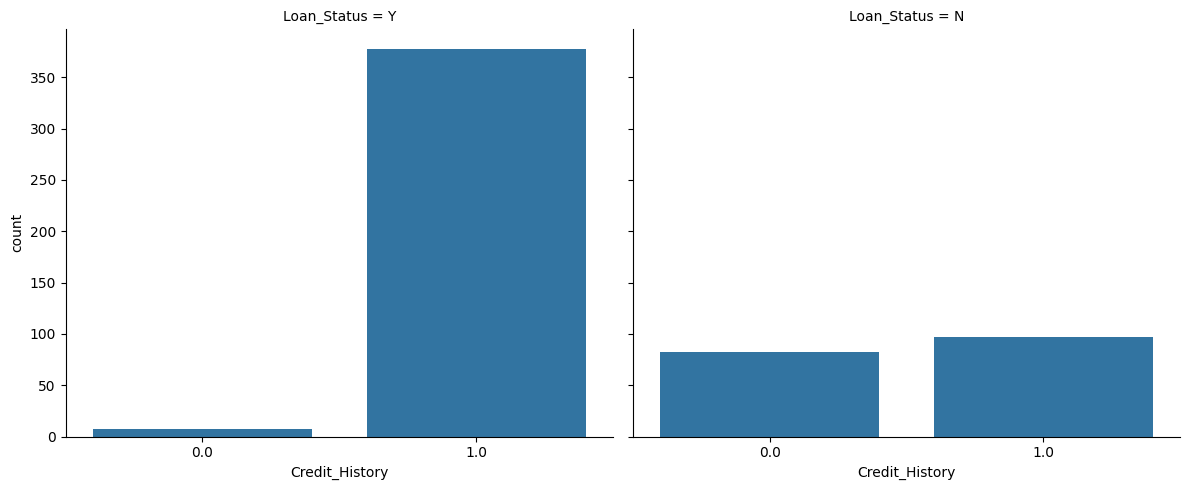

In [35]:
# Credit_history

grid=sns.FacetGrid(df, col="Loan_Status", height=5, aspect=1.2)
grid.map(sns.countplot, "Credit_History")


### On remarque ici que le refus n'est pas trop lié au fait qu'ils soint marié ou pas, mais en ce qui concerne l'acceptation la plus part de ceux qui beneficie d'un pret sont marié

/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:718: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


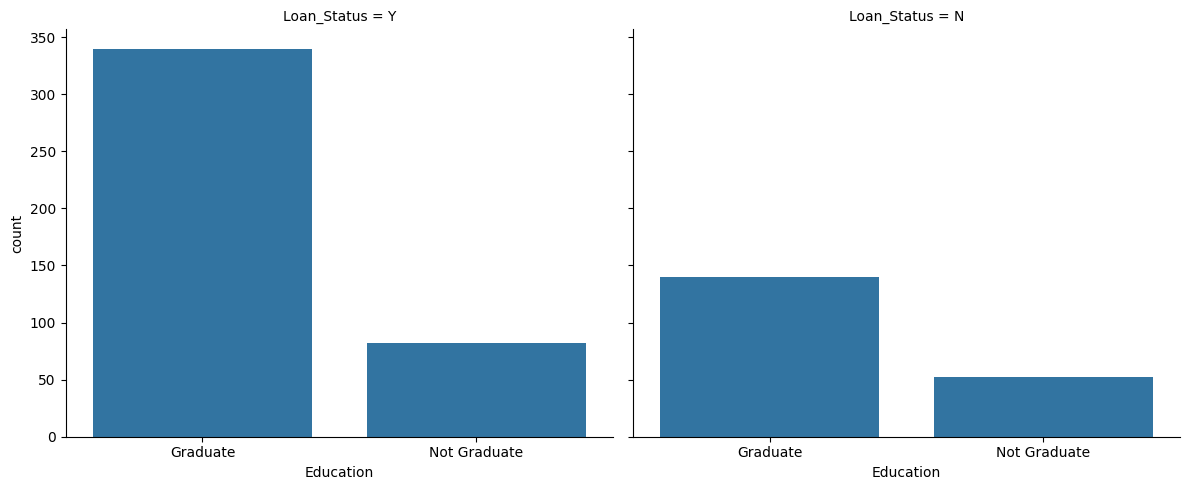

In [36]:
# Credit_history

grid=sns.FacetGrid(df, col="Loan_Status", height=5, aspect=1.2)
grid.map(sns.countplot, "Education")


### On remarque que la plupart de ceux qui beneficie d'un credit sont diplomé ou alors on t etudié

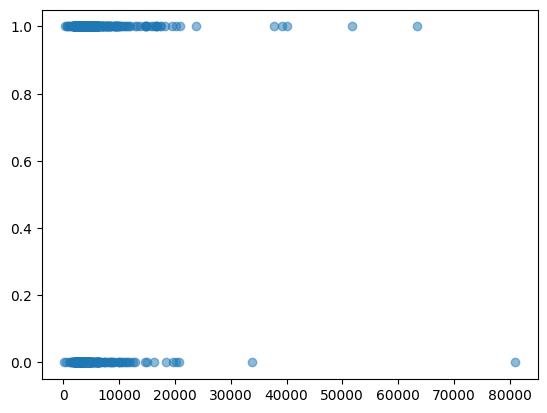

In [37]:
# Impacte du revenu du demandeur

plt.scatter(X['ApplicantIncome'], y, alpha=0.5)
# permet de visualiser la relation entre le revenu du demandeur et le statut du crédit. Chaque point représente une demande de crédit, avec l'axe des x représentant le revenu du demandeur et l'axe des y représentant le statut du crédit (0 pour refusé, 1 pour accordé). L'alpha=0.5 rend les points semi-transparents pour mieux visualiser les zones de densité.

In [38]:
# on remarque que la plupart des demandes de crédit sont concentrées dans la zone où le revenu du demandeur est inférieur à 10 000. Il y a également quelques demandes de crédit avec un revenu très élevé, mais elles sont beaucoup moins nombreuses.
# En conclusion, il semble y avoir une tendance générale selon laquelle les demandeurs ayant un revenu plus élevé ont plus de chances d'obtenir un crédit accordé, mais il existe également des exceptions à cette tendance.

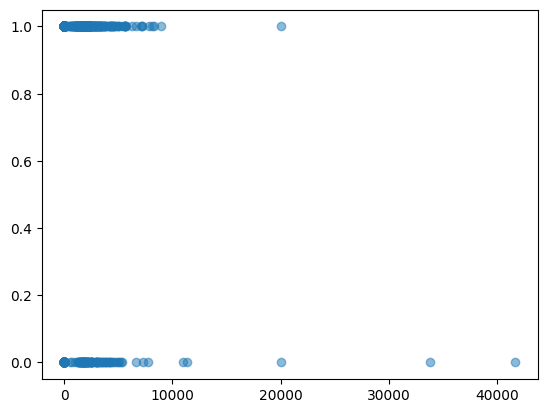

In [39]:
# Impacte du revenu du conjoint
plt.scatter(X['CoapplicantIncome'], y, alpha=0.5)


In [40]:
# On remarque que la plupart des demandes de crédit sont concentrées dans la zone où le revenu du conjoint est inférieur à 10 000. Il y a également quelques demandes de crédit avec un revenu très élevé, mais elles sont beaucoup moins nombreuses.
# En conclusion, il semble y avoir une tendance générale selon laquelle les demandeurs ayant un revenu plus élevé ont plus de chances d'obtenir un crédit accordé, mais il existe également des exceptions à cette tendance.

In [41]:
df.groupby('Loan_Status').median(numeric_only=True) # permet de calculer la médiane de chaque variable en fonction du statut du crédit (0 ou N pour refusé, 1 ou Y pour accordé). Cela permet de voir si certaines variables ont un impact sur le fait d'obtenir un crédit ou pas.

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
Loan_Status,,,,,
N,3833.5,268.0,129.0,360.0,1.0
Y,3812.5,1239.5,126.0,360.0,1.0


### NB : On remarque que pour certaines variables, tel que CoapplicantIncome, le revenu du conjoint a un impacte sur la validation du pret, plus le revenu du conjoint est élévé, plus le pret est accepter, on remarque par exemple que pour LoanAmount le revenu du conjoint n'a pas d'impacte

## Fin de l'Analyse exploratoire

# Realisation d'un Model en se basant sur les algorithmes de Machine Learning (ML)

### Division de données en données de test et d'entrainement

In [42]:
# Importation des bibliothèques pour la modélisation
from sklearn.model_selection import train_test_split # Pour diviser les données en ensembles d'entraînement et de test
from sklearn.model_selection import StratifiedShuffleSplit  # Pour diviser les données en ensembles d'entraînement et de test de manière stratifiée

In [43]:
# Division des données en ensembles d'entraînement et de test de manière stratifiée

split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42) # n_splits=1 signifie que l'on va faire une seule division, test_size=0.2 signifie que l'on va utiliser 20% des données pour le test et 80% pour l'entraînement, random_state=42 permet de reproduire les mêmes résultats à chaque exécution du code
for train, test in split.split(X,y): # split.split(X,y) permet de diviser les données en ensembles d'entraînement et de test de manière stratifiée en fonction de la variable target y
    X_train = X.iloc[train] # X.iloc[train] permet de récupérer les lignes correspondant à l'ensemble d'entraînement
    y_train = y.iloc[train] # y.iloc[train] permet de récupérer les lignes correspondant à l'ensemble d'entraînement
    X_test = X.iloc[test]   # X.iloc[test] permet de récupérer les lignes correspondant à l'ensemble de test
    y_test = y.iloc[test]   # y.iloc[test] permet de récupérer les lignes correspondant à l'ensemble de test
print("Taille de X_train :", X_train.shape[0]) 
print("Taille de y_train :", y_train.shape[0])
print("Taille de X_test  :", X_test.shape[0])
print("Taille de y_test  :", y_test.shape[0])

Taille de X_train : 491
Taille de y_train : 491
Taille de X_test  : 123
Taille de y_test  : 123


In [44]:
# Creation de notre model de machine learning: 
# NB : Nous allons travailler avec 3 model et ensuite choisir le meuilleur
# Les algorithme choisi: ( 1: Logistic Regression, 2:KNN, 3:Decision Tree)

# Importation des bibliothèques pour la modélisation

from sklearn.linear_model import LogisticRegression # Pour la régression logistique
from sklearn.neighbors import KNeighborsClassifier  # Pour le classifieur KNN
from sklearn.tree import DecisionTreeClassifier     # Pour l'arbre de décision
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix # Pour évaluer les performances des modèles

In [45]:
# Création du modèle
modele_lr = LogisticRegression(random_state=42)

# Entraînement
modele_lr.fit(X_train, y_train)

# Prédictions
y_pred_lr = modele_lr.predict(X_test)

# Évaluation
print("=== RÉGRESSION LOGISTIQUE ===")
print(f"Accuracy : {accuracy_score(y_test, y_pred_lr):.4f}")

print("\nRapport de classification :")
print(classification_report(y_test, y_pred_lr))

print("Matrice de confusion :")
print(confusion_matrix(y_test, y_pred_lr))

=== RÉGRESSION LOGISTIQUE ===
Accuracy : 0.8537

Rapport de classification :
              precision    recall  f1-score   support

           0       0.92      0.58      0.71        38
           1       0.84      0.98      0.90        85

    accuracy                           0.85       123
   macro avg       0.88      0.78      0.81       123
weighted avg       0.86      0.85      0.84       123

Matrice de confusion :
[[22 16]
 [ 2 83]]


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


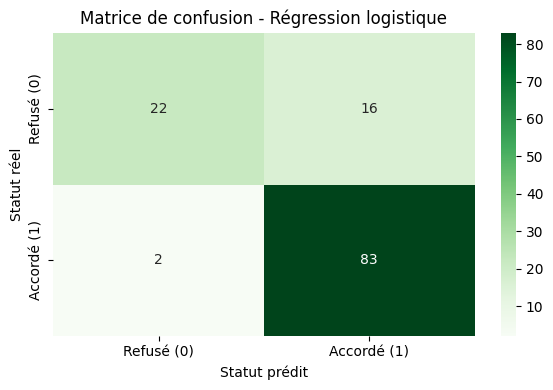

In [50]:
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=[0, 1])

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Refusé (0)', 'Accordé (1)'],
    yticklabels=['Refusé (0)', 'Accordé (1)']
)

plt.title('Matrice de confusion - Régression logistique')
plt.xlabel('Statut prédit')
plt.ylabel('Statut réel')
plt.tight_layout()
plt.show()

### Le resultat de Logistic regression montre sur la premiere ligne que le model predit correctement 22 refus mais predit aussi 16 accord alors qu'en realité cetait refusé dans les données historiques


### Sur la 2eme ligne, le model predit correctement 83 accord  mais predit aussi 2 refus alors qu'en realité ca été accordé dans les données historiques

In [46]:
# Création du modèle
modele_knn = KNeighborsClassifier()

# Entraînement
modele_knn.fit(X_train, y_train)

# Prédictions
y_pred_knn = modele_knn.predict(X_test)

# Évaluation
print("=== K NEAREST NEIGHBORS ===")
print(f"Accuracy : {accuracy_score(y_test, y_pred_knn):.4f}")

print("\nRapport de classification :")
print(classification_report(y_test, y_pred_knn))

print("Matrice de confusion :")
print(confusion_matrix(y_test, y_pred_knn))

=== K NEAREST NEIGHBORS ===
Accuracy : 0.6504

Rapport de classification :
              precision    recall  f1-score   support

           0       0.41      0.29      0.34        38
           1       0.72      0.81      0.76        85

    accuracy                           0.65       123
   macro avg       0.56      0.55      0.55       123
weighted avg       0.62      0.65      0.63       123

Matrice de confusion :
[[11 27]
 [16 69]]


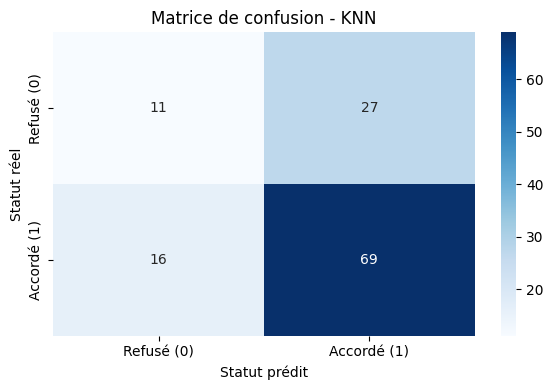

In [52]:
cm_knn = confusion_matrix(y_test, y_pred_knn, labels=[0, 1])

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Refusé (0)', 'Accordé (1)'],
    yticklabels=['Refusé (0)', 'Accordé (1)']
)

plt.title('Matrice de confusion - KNN')
plt.xlabel('Statut prédit')
plt.ylabel('Statut réel')
plt.tight_layout()
plt.show()

In [47]:
# Création du modèle
modele_dt = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

# Entraînement
modele_dt.fit(X_train, y_train)

# Prédictions
y_pred_dt = modele_dt.predict(X_test)

# Évaluation
print("=== ARBRE DE DÉCISION ===")
print(f"Accuracy : {accuracy_score(y_test, y_pred_dt):.4f}")

print("\nRapport de classification :")
print(classification_report(y_test, y_pred_dt))

print("Matrice de confusion :")
print(confusion_matrix(y_test, y_pred_dt))

=== ARBRE DE DÉCISION ===
Accuracy : 0.8455

Rapport de classification :
              precision    recall  f1-score   support

           0       0.91      0.55      0.69        38
           1       0.83      0.98      0.90        85

    accuracy                           0.85       123
   macro avg       0.87      0.76      0.79       123
weighted avg       0.86      0.85      0.83       123

Matrice de confusion :
[[21 17]
 [ 2 83]]


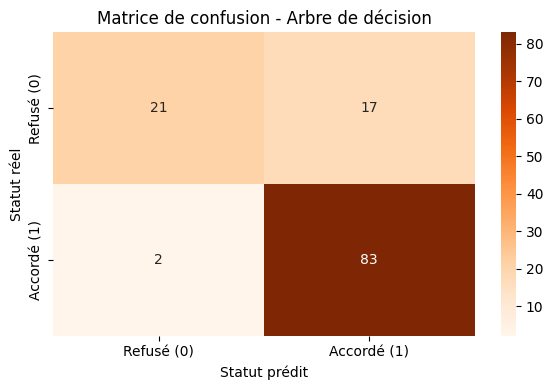

In [53]:
cm_dt = confusion_matrix(y_test, y_pred_dt, labels=[0, 1])

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Refusé (0)', 'Accordé (1)'],
    yticklabels=['Refusé (0)', 'Accordé (1)']
)

plt.title('Matrice de confusion - Arbre de décision')
plt.xlabel('Statut prédit')
plt.ylabel('Statut réel')
plt.tight_layout()
plt.show()

## En conclusion le model qui a fourni le meuilleur resultat est la REGRESSION LOGISTIC avec un Accuracy de 85

### Pour l'implementation de notre model dans l'application , sur les 11 variables nous allons choisir quelques variables qui ont plus d'impacte sur le models ou sur le resultat

In [68]:
# Creation d'une nouvelle base de données en choisissant quelque variables importante


X_2 = X[['Credit_History', 'Gender', 'Married', 'CoapplicantIncome',  'ApplicantIncome']]

In [69]:
# Division des données en ensembles d'entraînement et de test de manière stratifiée

split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42) # n_splits=1 signifie que l'on va faire une seule division, test_size=0.2 signifie que l'on va utiliser 20% des données pour le test et 80% pour l'entraînement, random_state=42 permet de reproduire les mêmes résultats à chaque exécution du code
for train, test in split.split(X_2,y): # split.split(X_2,y) permet de diviser les données en ensembles d'entraînement et de test de manière stratifiée en fonction de la variable target y
    X_2_train = X_2.iloc[train] # X_2.iloc[train] permet de récupérer les lignes correspondant à l'ensemble d'entraînement
    y_2_train = y.iloc[train] # y.iloc[train] permet de récupérer les lignes correspondant à l'ensemble d'entraînement
    X_2_test = X_2.iloc[test]   # X_2.iloc[test] permet de récupérer les lignes correspondant à l'ensemble de test
    y_2_test = y.iloc[test]   # y.iloc[test] permet de récupérer les lignes correspondant à l'ensemble de test
print("Taille de X_2_train :", X_2_train.shape) 
print("Taille de y_2_train   :", y_2_train.shape)
print("Taille de X_2_test  :", X_2_test.shape)
print("Taille de y_2_test    :", y_2_test.shape)

Taille de X_2_train : (491, 5)
Taille de y_2_train   : (491,)
Taille de X_2_test  : (123, 5)
Taille de y_2_test    : (123,)


In [70]:
# Création du modèle
modele_lr_2 = LogisticRegression(random_state=42)

# Entraînement
modele_lr_2.fit(X_2_train, y_2_train)

# Prédictions
y_pred_lr_2 = modele_lr_2.predict(X_2_test)

# Évaluation
print("=== RÉGRESSION LOGISTIQUE ===")
print(f"Accuracy : {accuracy_score(y_2_test, y_pred_lr_2):.4f}")

print("\nRapport de classification :")
print(classification_report(y_2_test, y_pred_lr_2))

print("Matrice de confusion :")
print(confusion_matrix(y_2_test, y_pred_lr_2))

=== RÉGRESSION LOGISTIQUE ===
Accuracy : 0.8537

Rapport de classification :
              precision    recall  f1-score   support

           0       0.92      0.58      0.71        38
           1       0.84      0.98      0.90        85

    accuracy                           0.85       123
   macro avg       0.88      0.78      0.81       123
weighted avg       0.86      0.85      0.84       123

Matrice de confusion :
[[22 16]
 [ 2 83]]


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [71]:
# Création du modèle
modele_knn_2 = KNeighborsClassifier()

# Entraînement
modele_knn_2.fit(X_2_train, y_2_train)

# Prédictions
y_pred_knn_2 = modele_knn_2.predict(X_2_test)

# Évaluation
print("=== K NEAREST NEIGHBORS ===")
print(f"Accuracy : {accuracy_score(y_2_test, y_pred_knn_2):.4f}")

print("\nRapport de classification :")
print(classification_report(y_2_test, y_pred_knn_2))

print("Matrice de confusion :")
print(confusion_matrix(y_2_test, y_pred_knn_2))

=== K NEAREST NEIGHBORS ===
Accuracy : 0.6585

Rapport de classification :
              precision    recall  f1-score   support

           0       0.43      0.34      0.38        38
           1       0.73      0.80      0.76        85

    accuracy                           0.66       123
   macro avg       0.58      0.57      0.57       123
weighted avg       0.64      0.66      0.65       123

Matrice de confusion :
[[13 25]
 [17 68]]


In [ ]:
# Création du modèle
modele_dt_2 = DecisionTreeClassifier(
    max_depth=1,
    random_state=42 # Permet de reproduire les mêmes résultats à chaque exécution du code
)

# Entraînement
modele_dt_2.fit(X_2_train, y_2_train)

# Prédictions
y_pred_dt_2 = modele_dt_2.predict(X_2_test)

# Évaluation
print("=== ARBRE DE DÉCISION ===")
print(f"Accuracy : {accuracy_score(y_2_test, y_pred_dt_2):.4f}")

print("\nRapport de classification :")
print(classification_report(y_2_test, y_pred_dt_2))

print("Matrice de confusion :")
print(confusion_matrix(y_2_test, y_pred_dt_2))

=== ARBRE DE DÉCISION ===
Accuracy : 0.8455

Rapport de classification :
              precision    recall  f1-score   support

           0       0.91      0.55      0.69        38
           1       0.83      0.98      0.90        85

    accuracy                           0.85       123
   macro avg       0.87      0.76      0.79       123
weighted avg       0.86      0.85      0.83       123

Matrice de confusion :
[[21 17]
 [ 2 83]]


# Fin de la partie entrainement de models

# Integration du model dans un logiciel developpé avec flask